# 04-Dify知识库与RAG应用：从文档处理到LOL游戏助手

本篇对应课程第 4 章《RAG 技术应用》，沿着“为什么需要 RAG、知识库如何构建、如何在 Dify 中接入 Agent”三步展开，最后实现一个基于英雄攻略资料的 LOL 游戏助手。

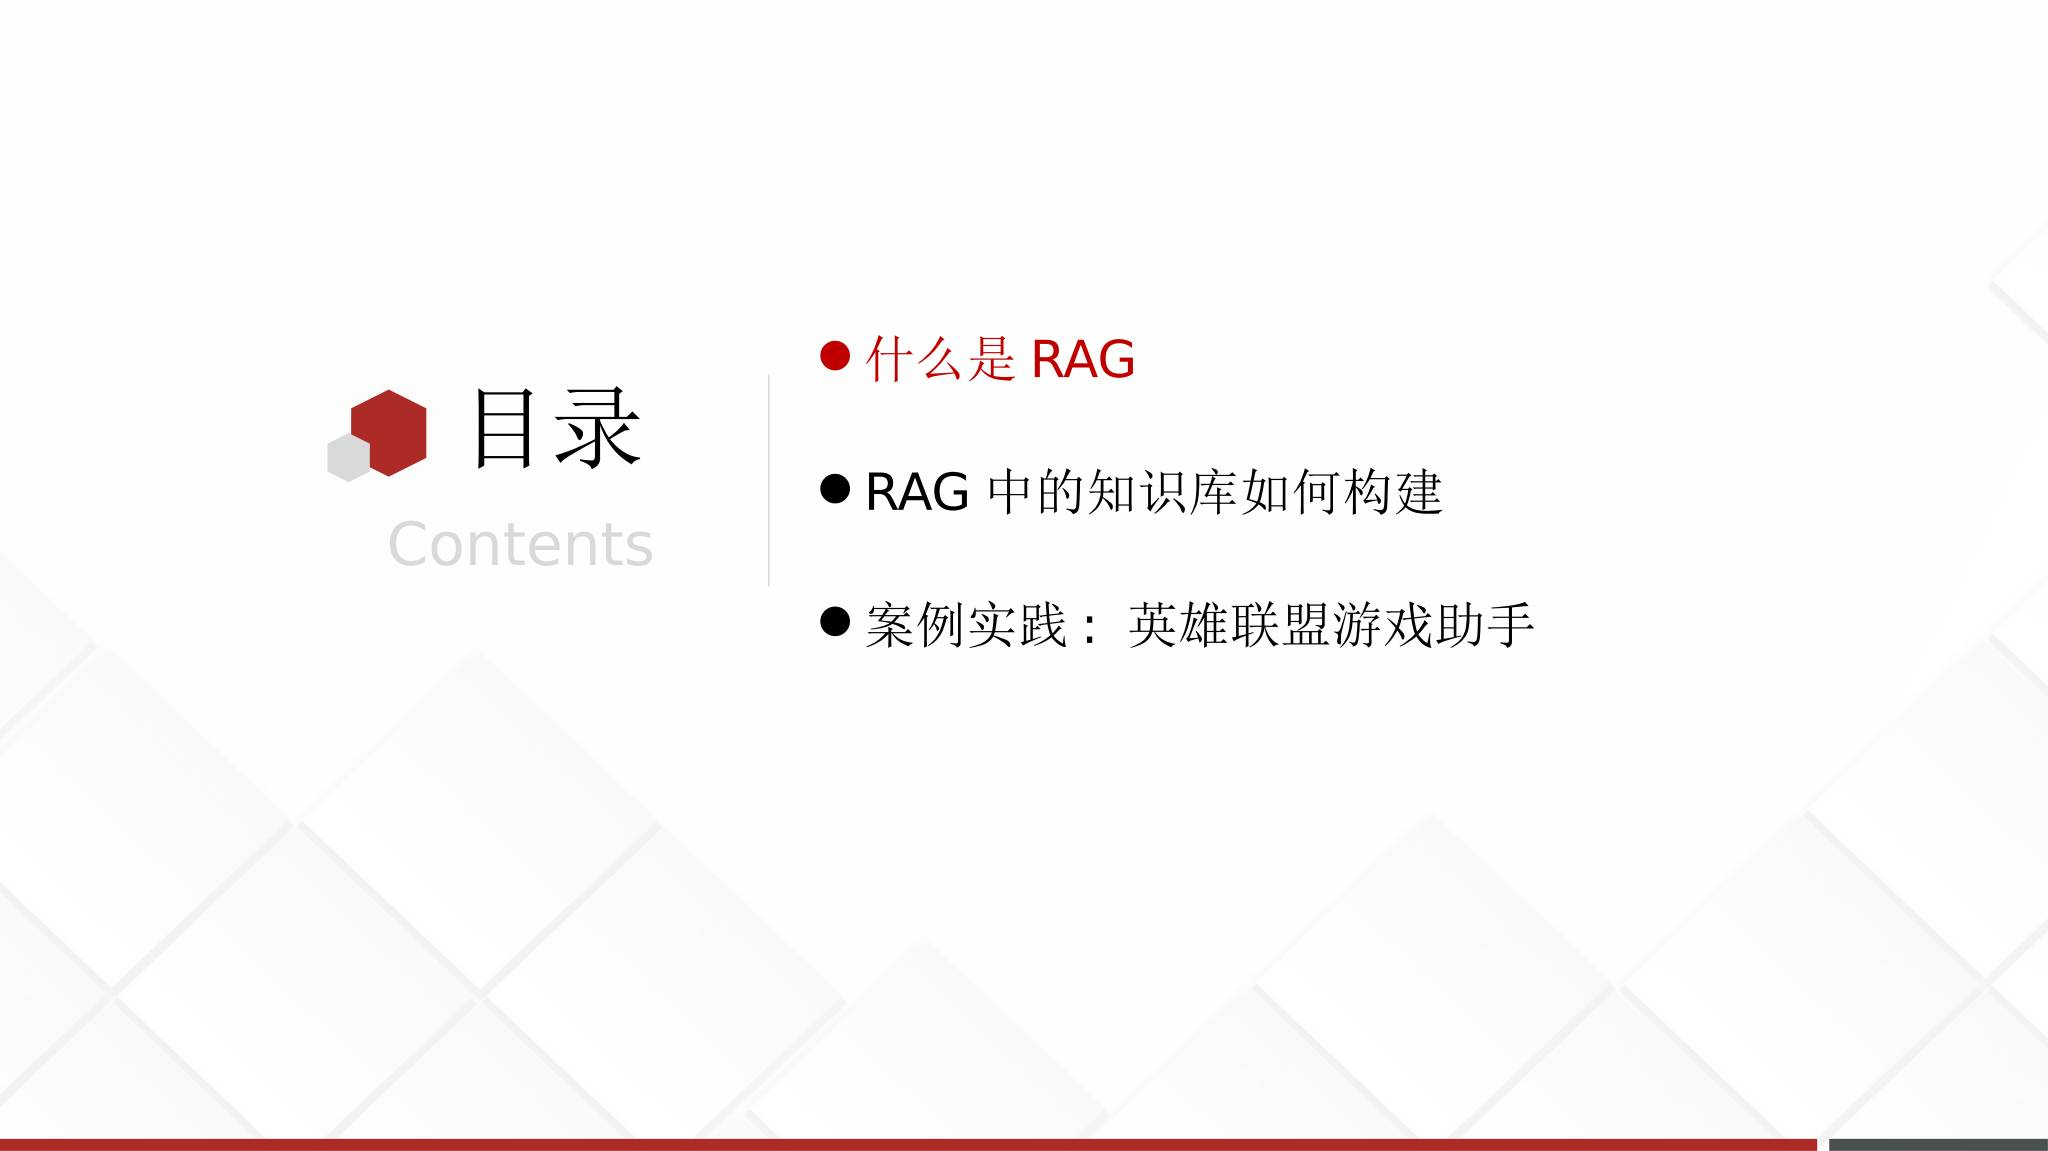


## 1. 为什么需要 RAG

课程用游戏攻略问答引入问题：用户询问某个英雄的技能，普通大模型可能因为知识滞后而无法回答，或者给出与当前资料不一致的内容。这样的回答会降低用户对助手的信任。

课件把问题归纳为：

- 模型知识可能过时，不能直接获得最新资料。
- 没有接入业务文档时，模型不了解特定领域内容。
- 回答无法引用用户提供的资料，结果难以核对。

解决思路是把相关资料放入知识库，在生成回答前先检索相关内容。

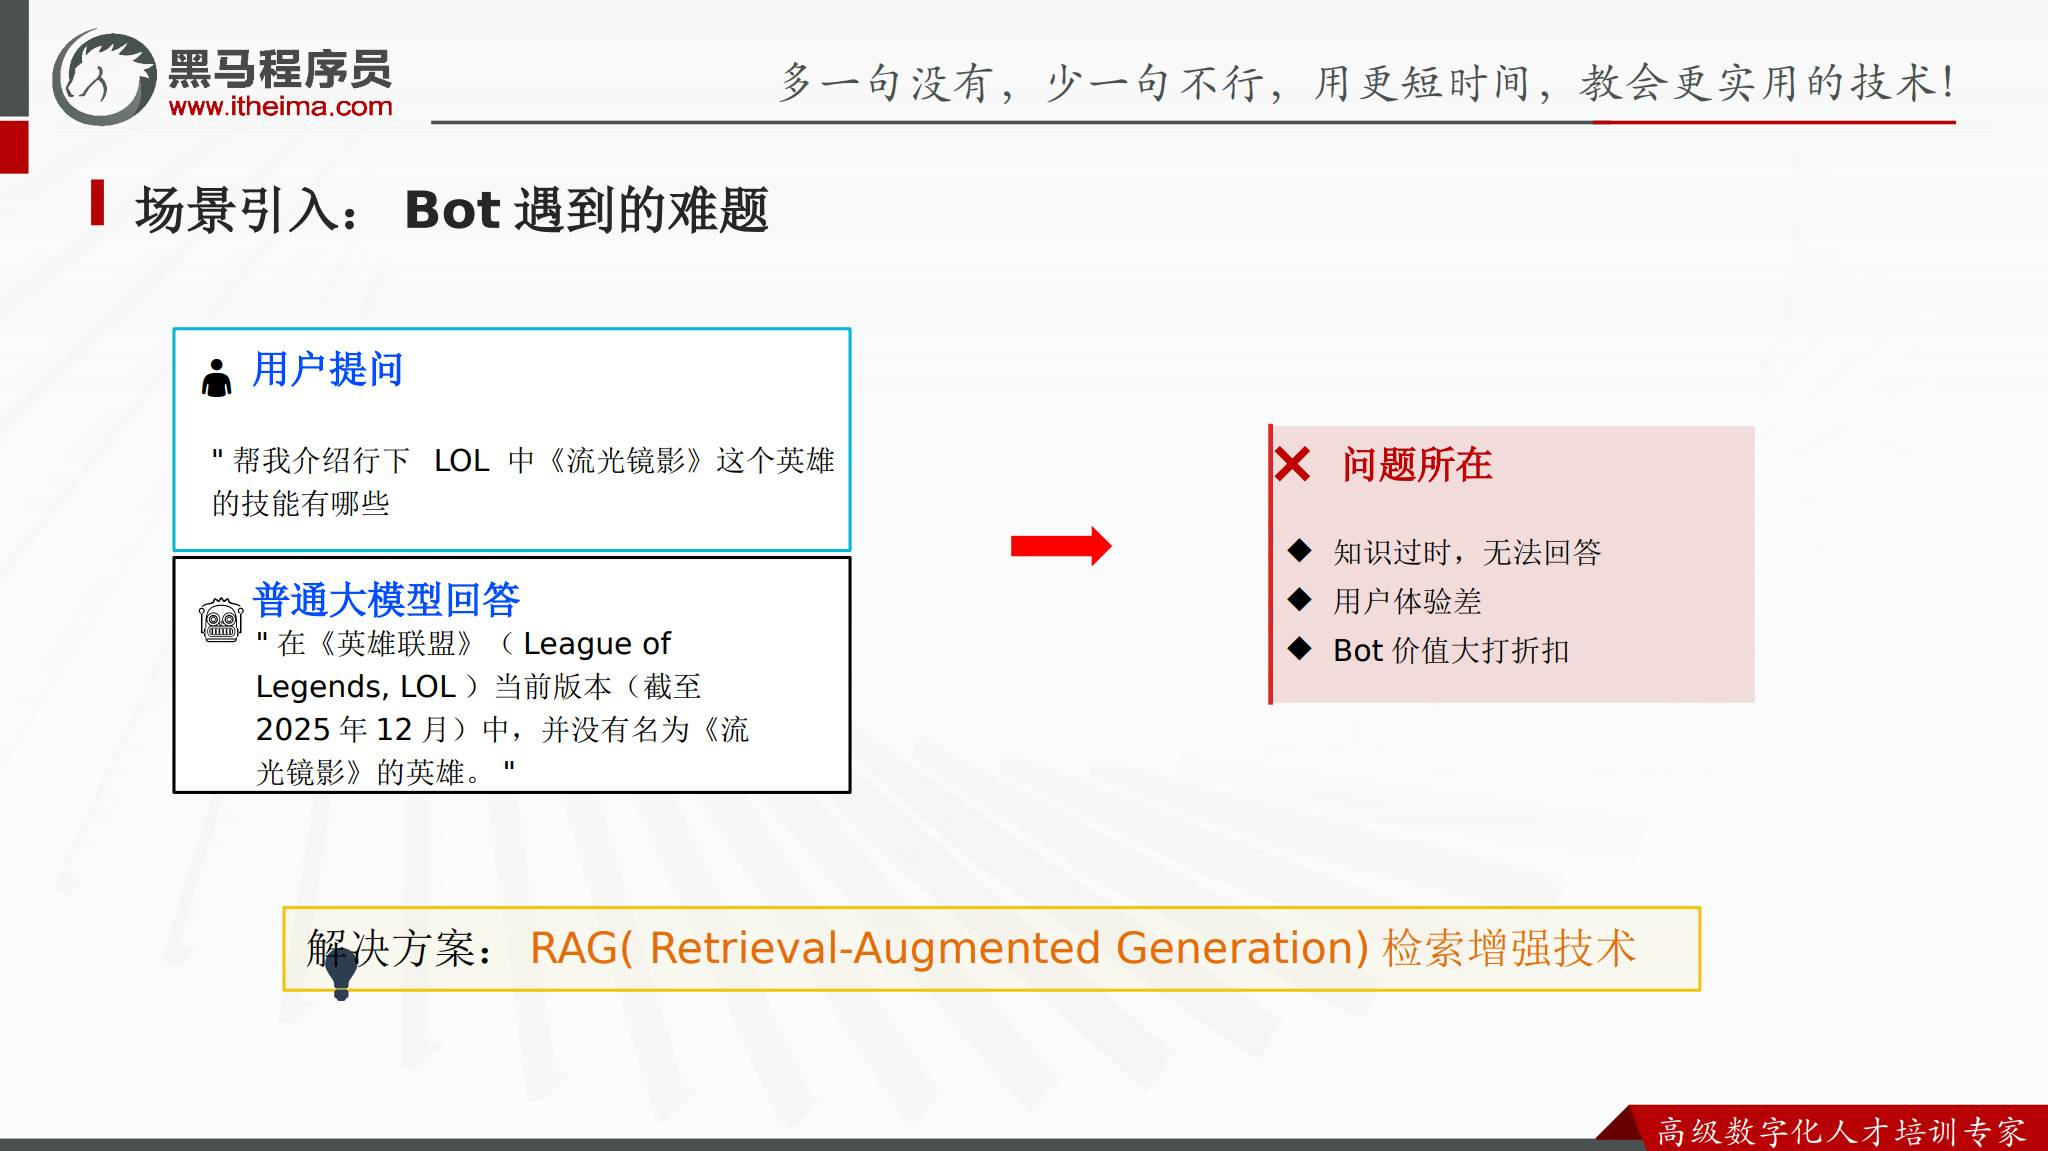


## 2. 什么是 RAG

RAG（Retrieval-Augmented Generation，检索增强生成）是一种结合知识检索和语言生成的技术，课程将它用于缓解大语言模型的幻觉问题。

基本过程是：

1. 用户提出问题。
2. 系统先从知识库检索与问题相关的文档片段。
3. 将原始问题和检索到的上下文一起交给大模型。
4. 大模型根据这些内容生成最终答案。

因此，RAG 把“查资料”和“组织回答”连接起来。知识库负责提供上下文，大模型负责理解上下文并生成自然语言结果。

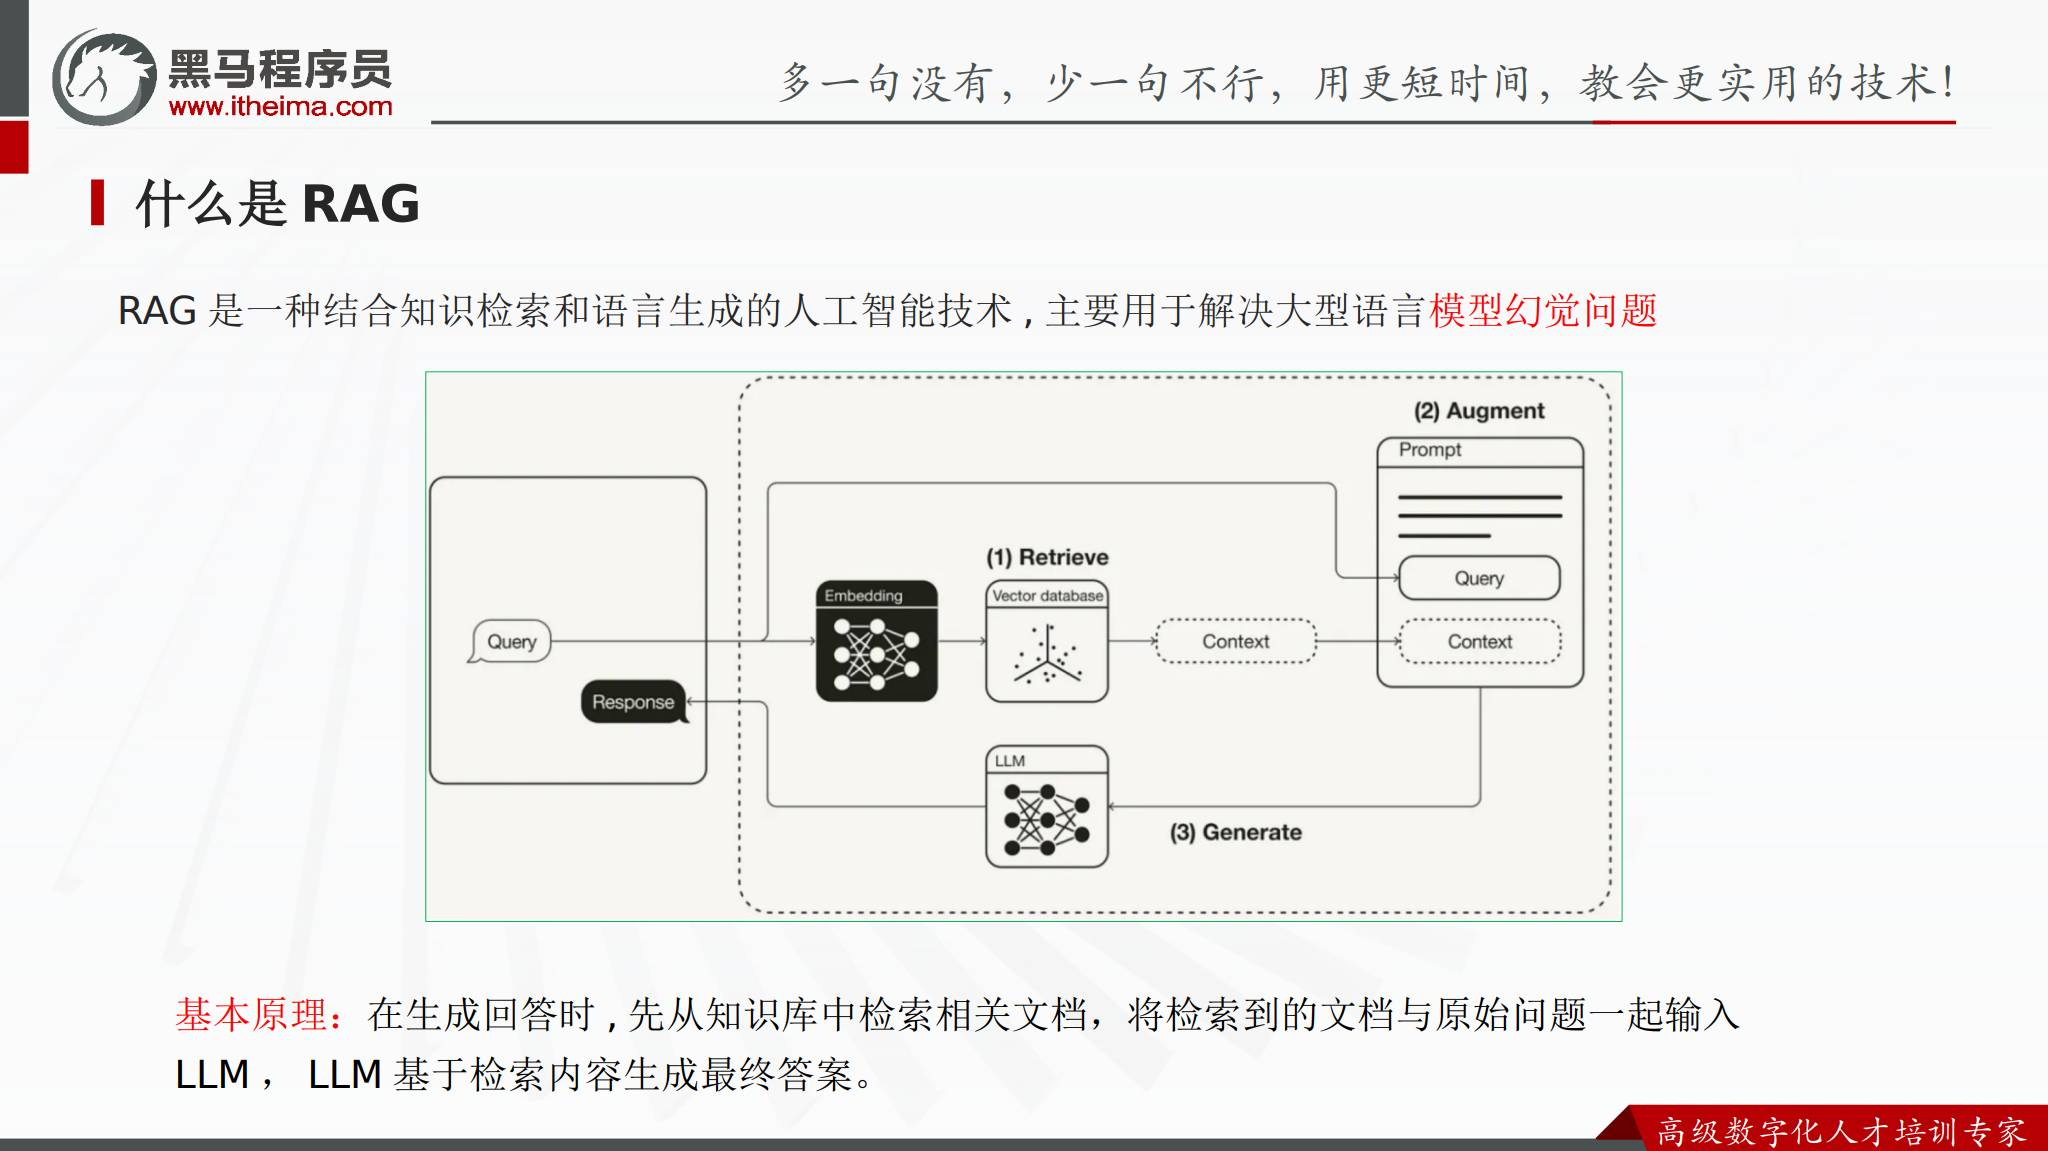


## 3. RAG 解决什么问题

RAG 主要针对传统 LLM 的消息滞后和领域知识不足。它不能自动保证所有回答正确，效果仍然取决于资料质量、切片方式、向量化模型和检索设置，但它为模型增加了可更新的知识来源。

可以用下面的链路记忆：

```text
问题 → 检索知识库 → 获取相关上下文 → 问题和上下文一起送入大模型 → 生成回答
```


## 4. 知识库构建第一步：准备文档

课件列出的常见资料类型和用途如下：

| 资料类型 | 支持格式 | 适用场景 | LOL 案例 |
| --- | --- | --- | --- |
| 文档 | PDF、Word、TXT | 攻略文章、教程文档 | 英雄攻略 PDF |
| 表格 | Excel、CSV | 结构化数据、统计信息 | 英雄属性表 |

上传前需要先处理原始资料：

- 清理广告、水印等无关内容。
- 按主题分类整理。
- 使用包含关键信息的规范文件名。

资料准备得越清楚，后续切片和检索越容易得到相关内容。

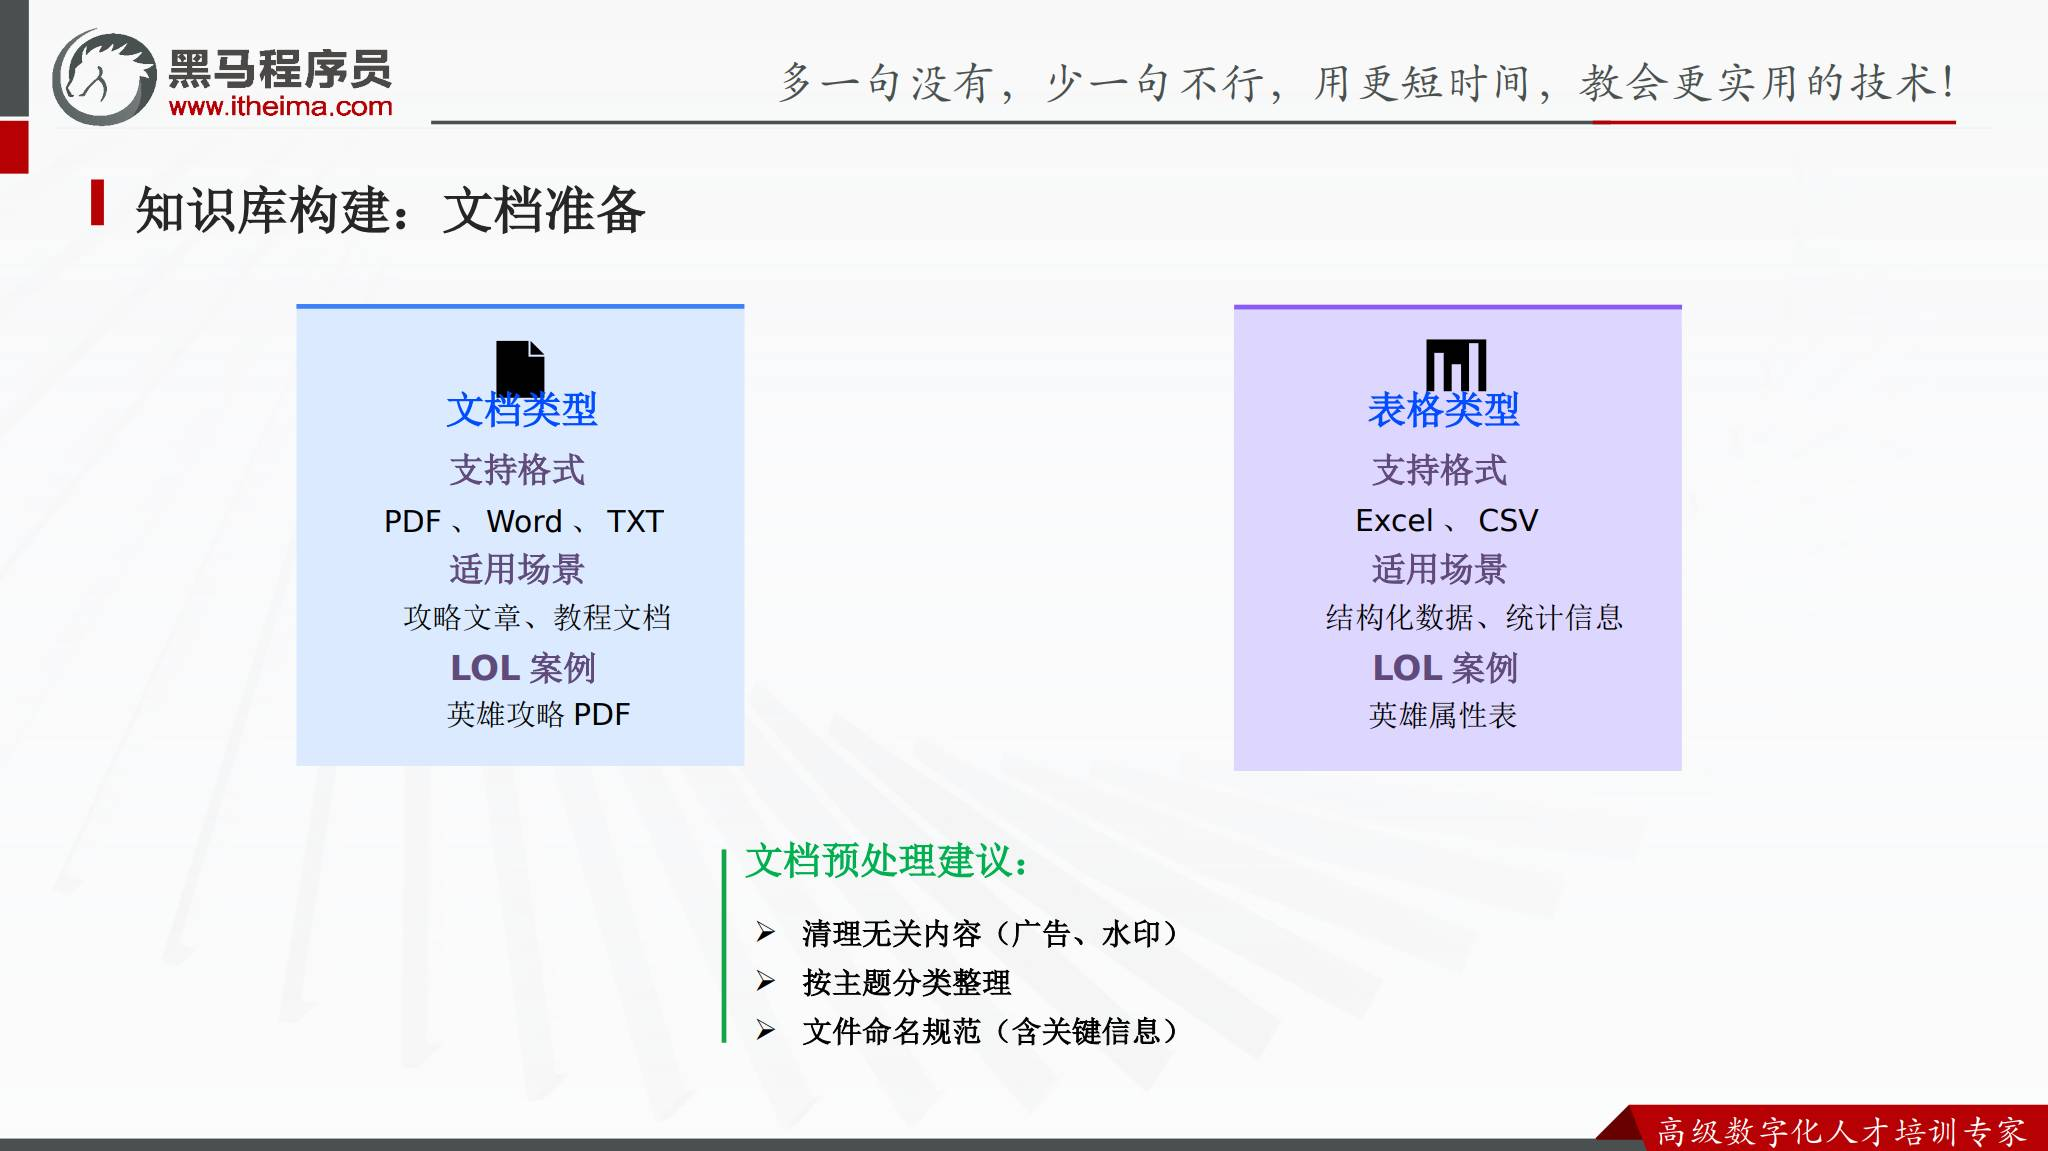


## 5. 知识库构建第二步：文档切片

文档切片就是把长文档拆成多个较小的文本片段。这样做有两个原因：适应大语言模型的上下文长度限制，并提升检索的精确度和效率。

课程介绍三种切分方式：

| 切分方式 | 做法 | 特点 |
| --- | --- | --- |
| 按字符数 | 固定长度，例如每 300 字一段 | 简单，长度容易控制 |
| 按符号 | 按句号、换行符、感叹号等分割 | 保留句子边界 |
| 按语义 | 识别主题变化点后切分 | 更贴近内容结构，但处理更复杂 |

课程建议把符号切分和字符长度结合起来，一般控制在每段 200 到 500 字。片段太小，上下文可能不完整；片段太大，无关信息会增多，干扰模型判断。

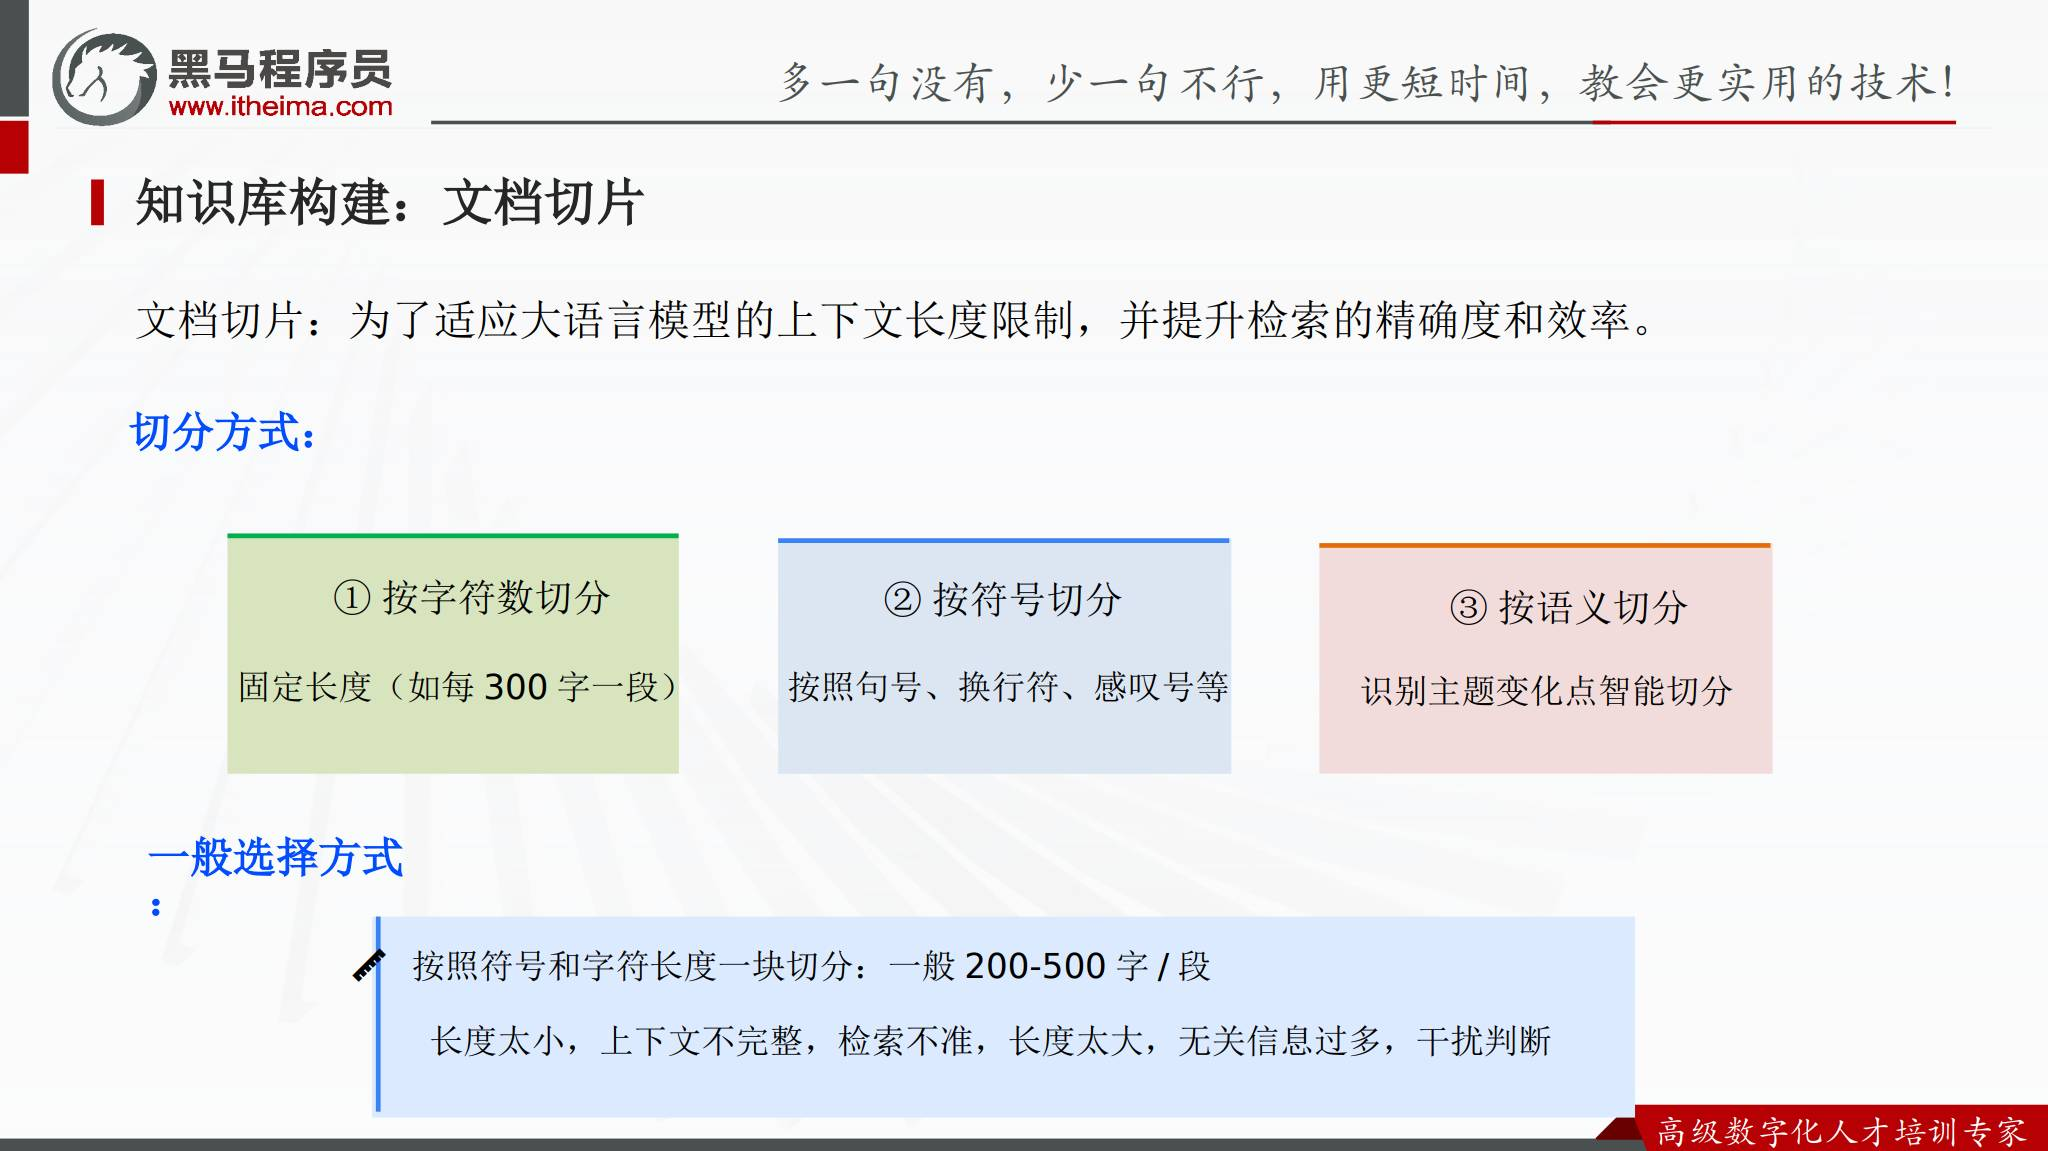


## 6. 知识库构建第三步：文档向量化

文档向量化是把切分后的文本转换成向量数字表示，以便计算问题和文档之间的相似性。

例如，用户问“盲僧 Q 技能”，系统会把问题和文档片段分别转换为向量：

```text
问题：盲僧 Q 技能 → [0.8, 0.6, ...]
文档：盲僧出装   → [0.7, 0.5, ...]
文档：烹饪技巧   → [0.1, 0.8, ...]
```

向量化让系统可以进行语义理解和相似度计算，并据此快速找到相关片段。它比较的是语义关联，不只是关键词是否完全相同。

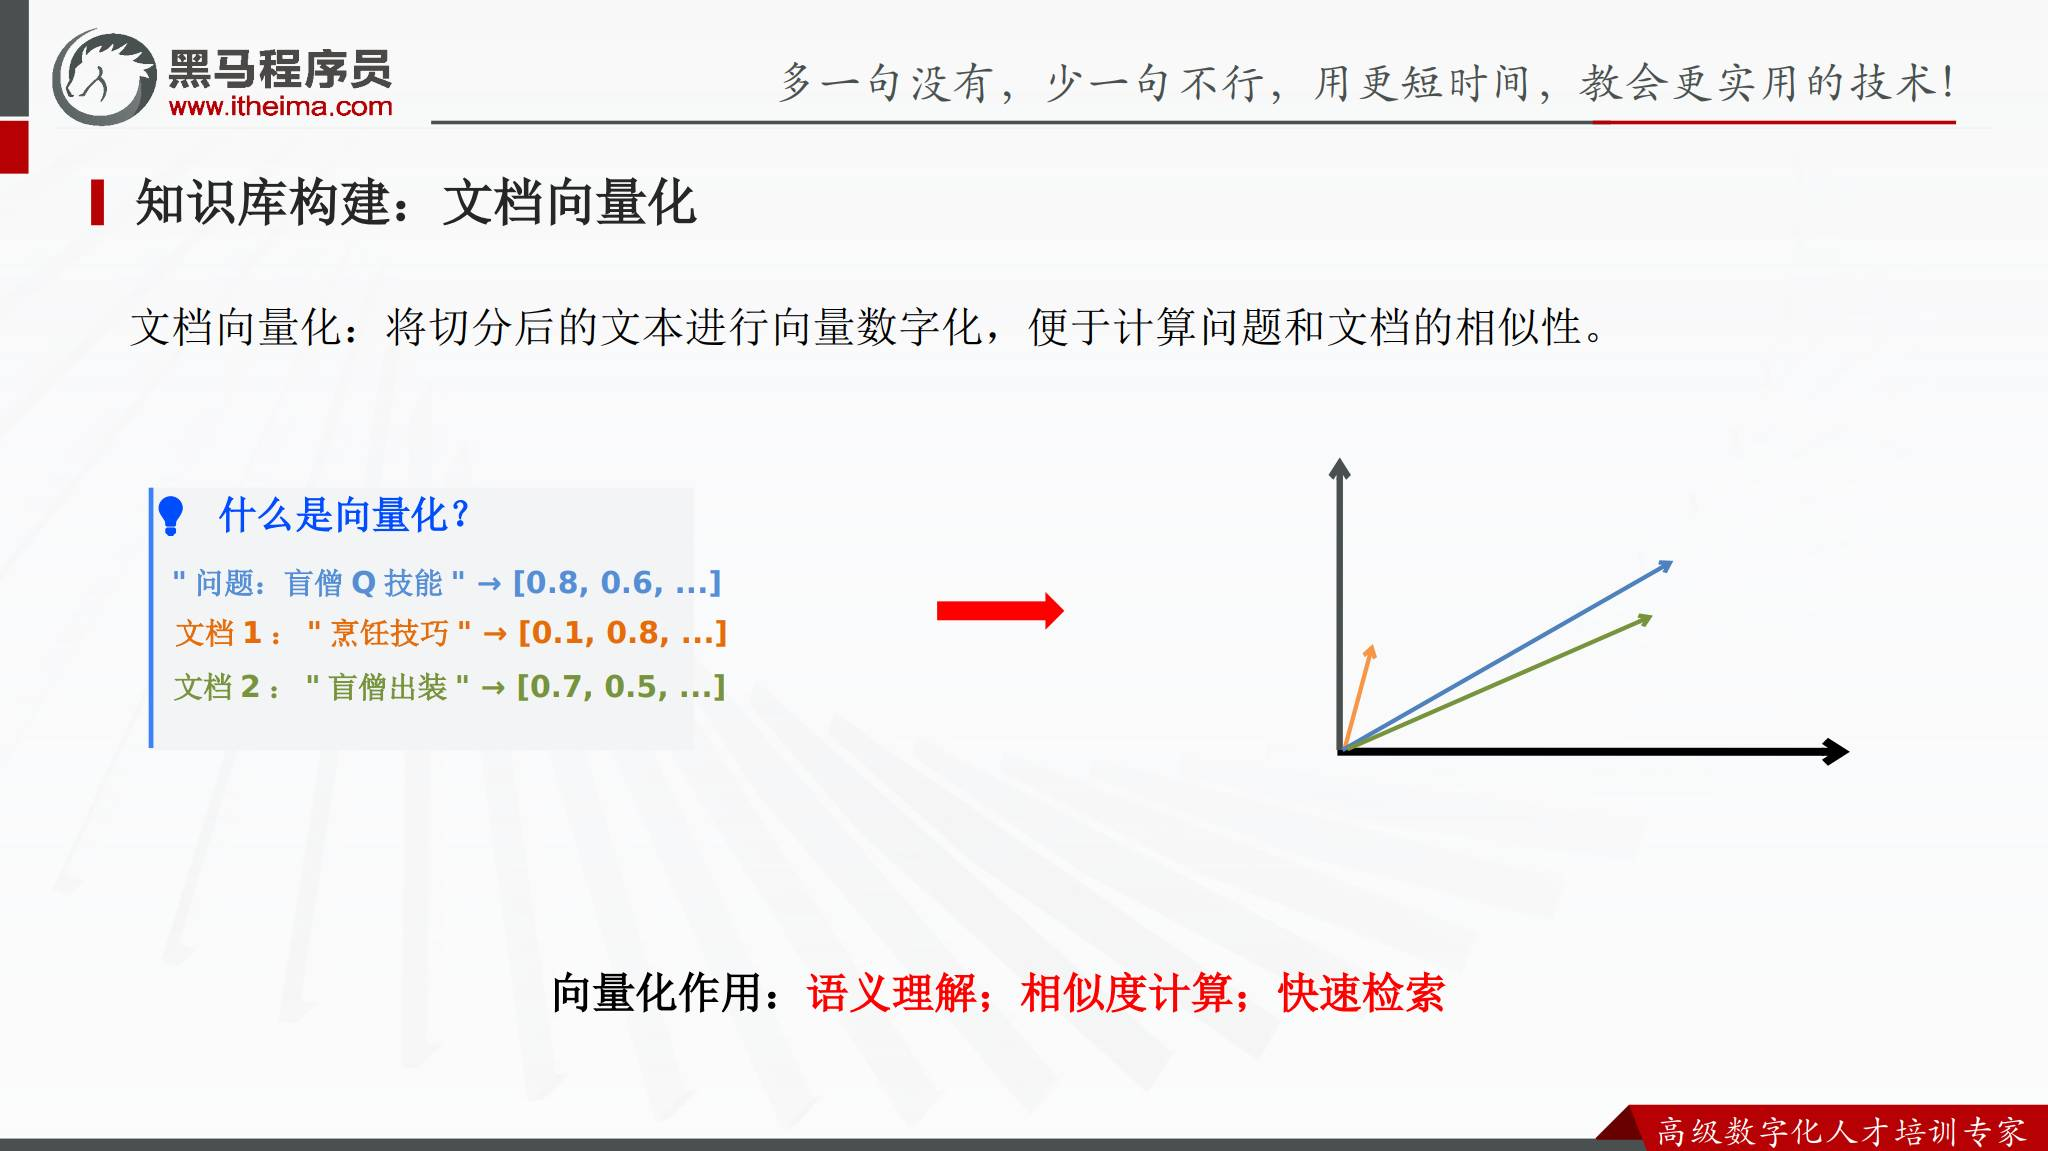


## 7. 知识库构建流程小结

RAG 知识库的基础流程是：

1. 准备文档。
2. 切分文档。
3. 将片段向量化。
4. 保存为可检索的知识库。

切片是为了适应上下文长度并提高检索精度，向量化是为了计算问题与文档片段的语义相似度。两者共同影响后续回答质量。


## 8. 在 Dify 中创建 LOL 攻略知识库

课件把知识库创建过程拆成六个操作环节：

1. **创建知识库**：进入 Dify，选择知识库创建入口。
2. **选择数据源**：上传准备好的文本或表格原始文件。
3. **文本分段**：在设置中选择分段方式，调整切片策略。
4. **构建索引**：将分段后的文档进行向量化。
5. **检索设置**：在向量检索、全文检索或混合检索中选择合适方式。
6. **查看结果**：预览文本处理效果，确认内容被正确分段和索引。

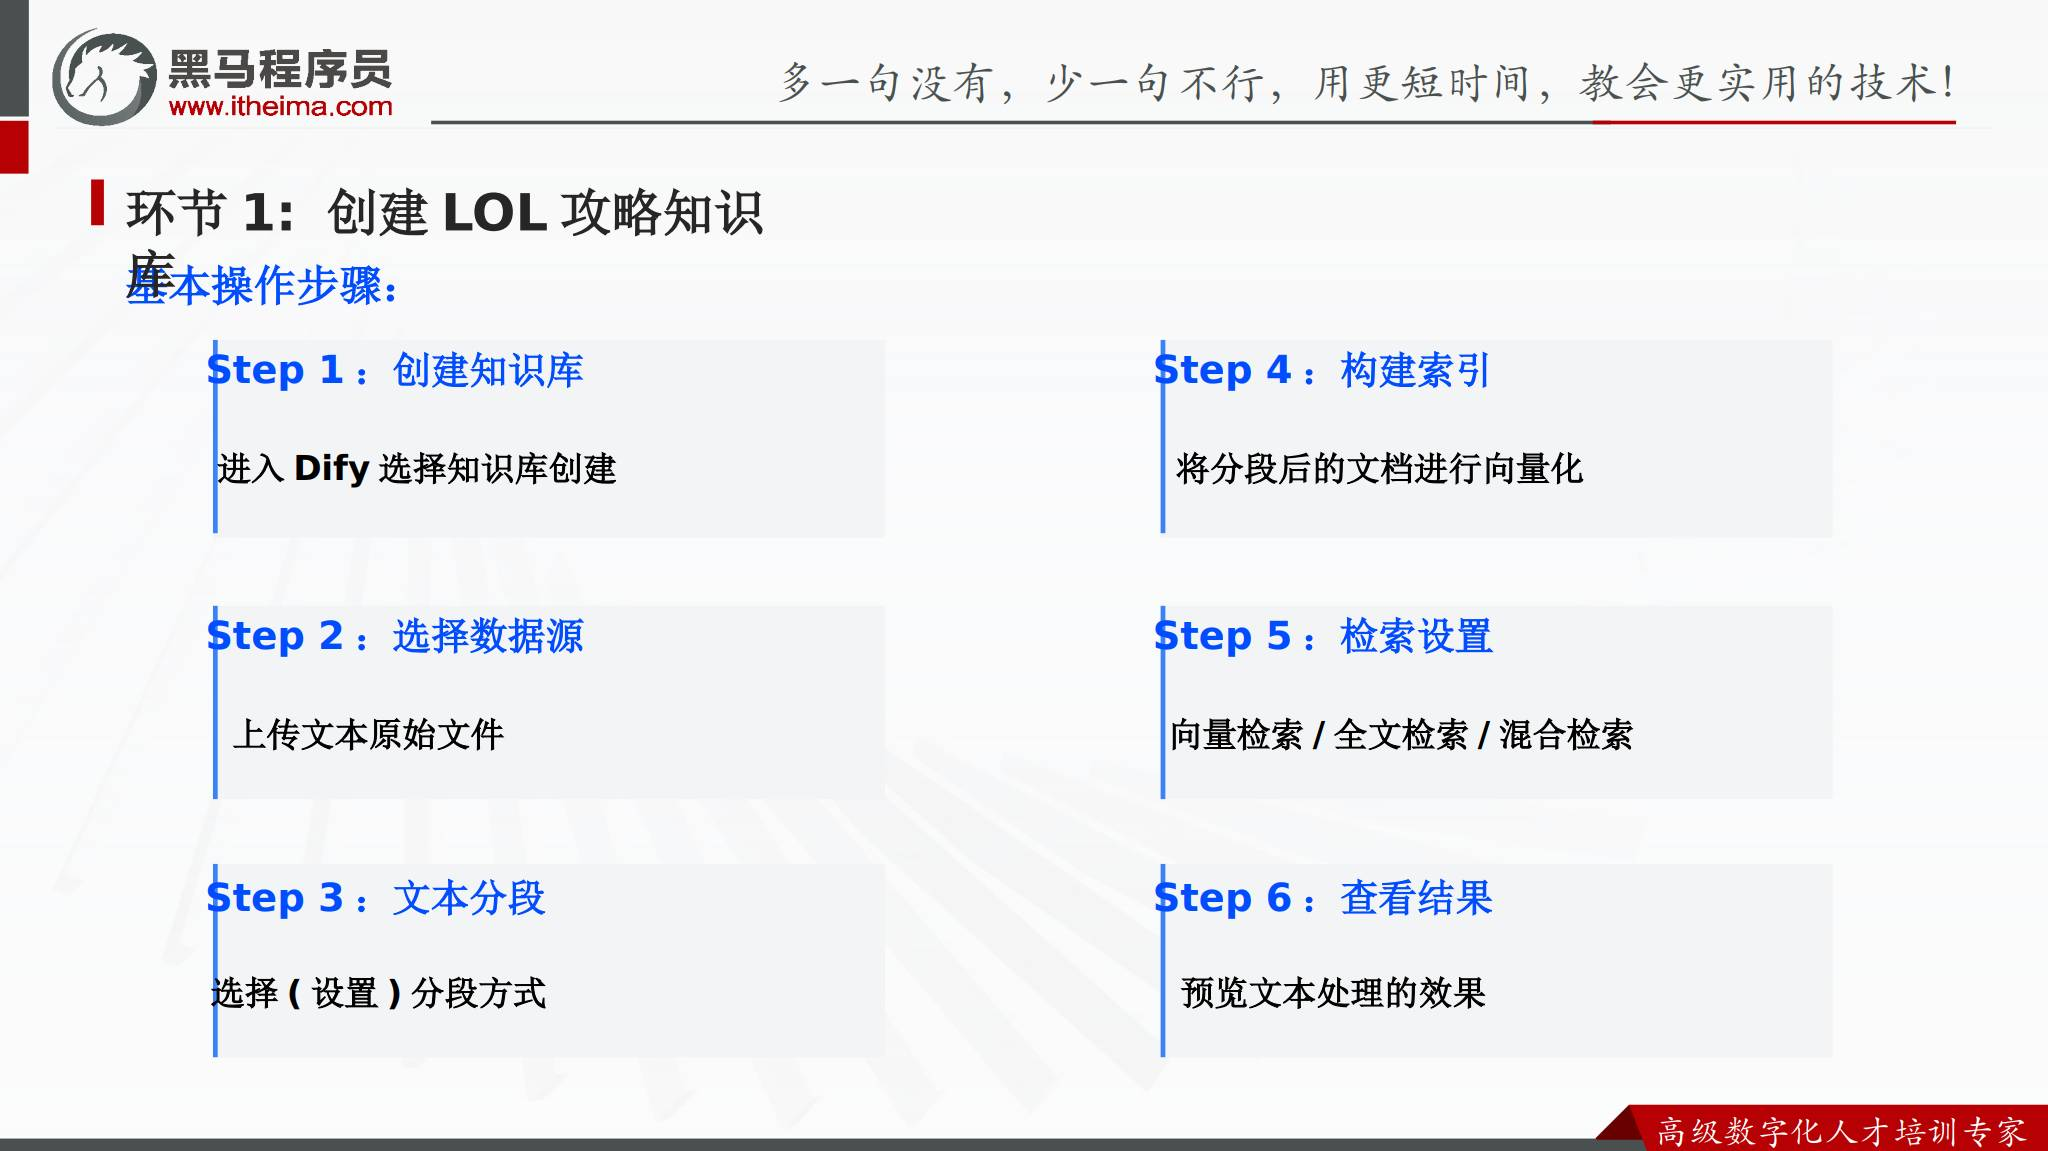


## 9. 检索方式怎么理解

课件列出三类检索设置：

| 检索方式 | 主要依据 | 适合关注点 |
| --- | --- | --- |
| 向量检索 | 文本语义相似度 | 用户说法与资料表述不同，但含义相近 |
| 全文检索 | 关键词或文本匹配 | 专有名词、英雄名、技能名等精确词汇 |
| 混合检索 | 综合语义和关键词结果 | 同时需要语义理解和精确匹配 |

实际使用时要通过预览和测试问题观察检索结果，而不是只凭名称选择。知识库内容、问题表达和模型能力都会影响效果。


## 10. 让 Agent 使用知识库

知识库创建完成后，需要把它关联到 Agent 应用：

1. 创建空白应用，选择构建 Agent 智能体。
2. 编写提示词，明确角色、功能和回复格式。
3. 在编排模块中选择“知识库”，点击“添加知识库”。
4. 选择刚刚创建的 LOL 攻略知识库。
5. 进入调试，输入问题并验证结果。

一个 Agent 可以关联多个知识库。课件提醒，可以通过设置优先级控制检索顺序，因此不同资料库之间要保持主题清晰，避免无关内容互相干扰。

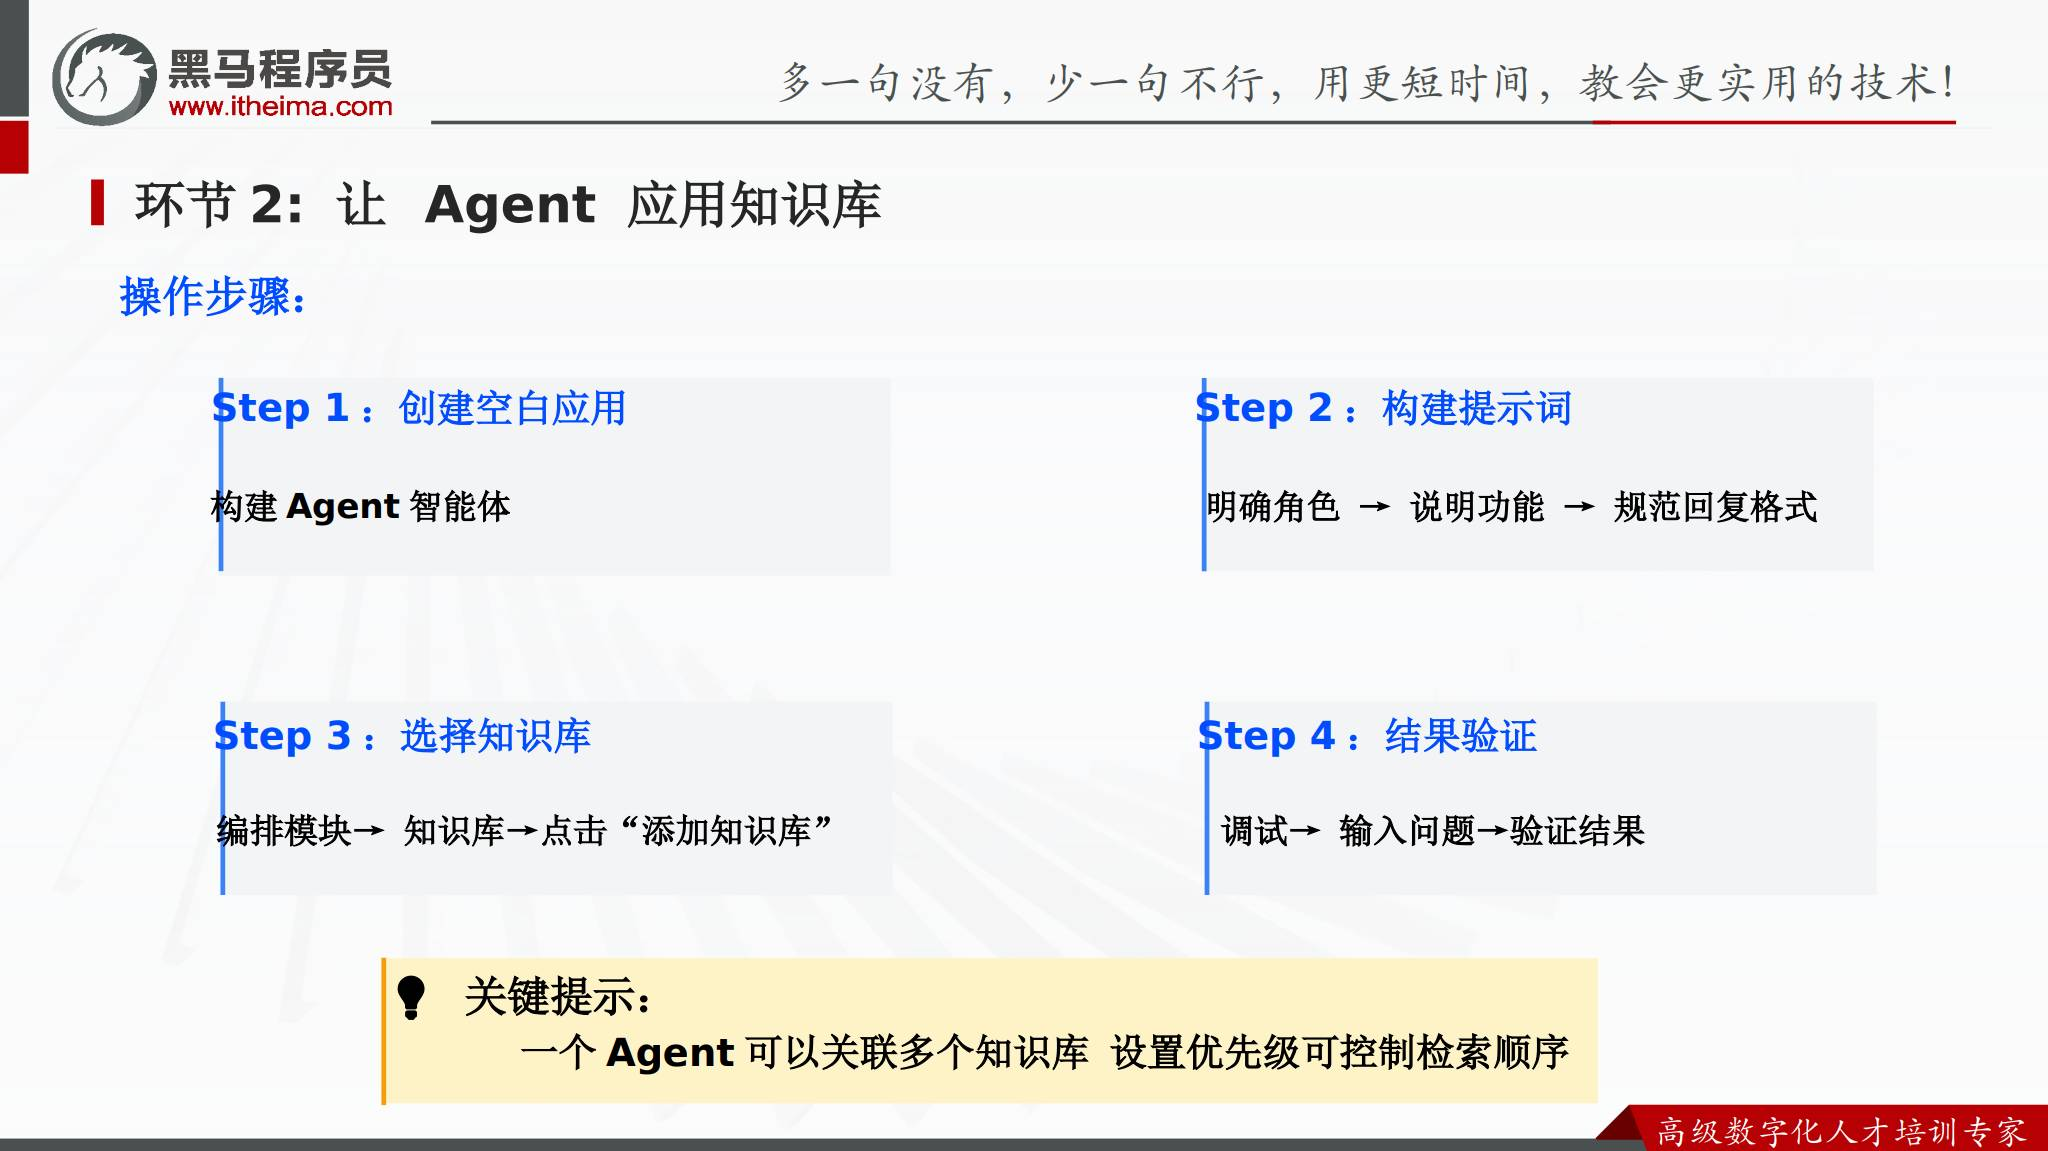


## 11. LOL 游戏助手的端到端链路

课程最后把整个案例总结为九个环节：

1. 上传文件。
2. 文档切分。
3. 文档向量化。
4. 存储知识库。
5. 根据问题检索知识库。
6. 获取相关上下文。
7. 将问题和上下文融合。
8. 把融合后的内容送入大模型。
9. 得到预测结果并返回给用户。

这条链路说明，Agent 的回答不是直接凭模型记忆生成，而是先使用知识库补充当前任务需要的资料。

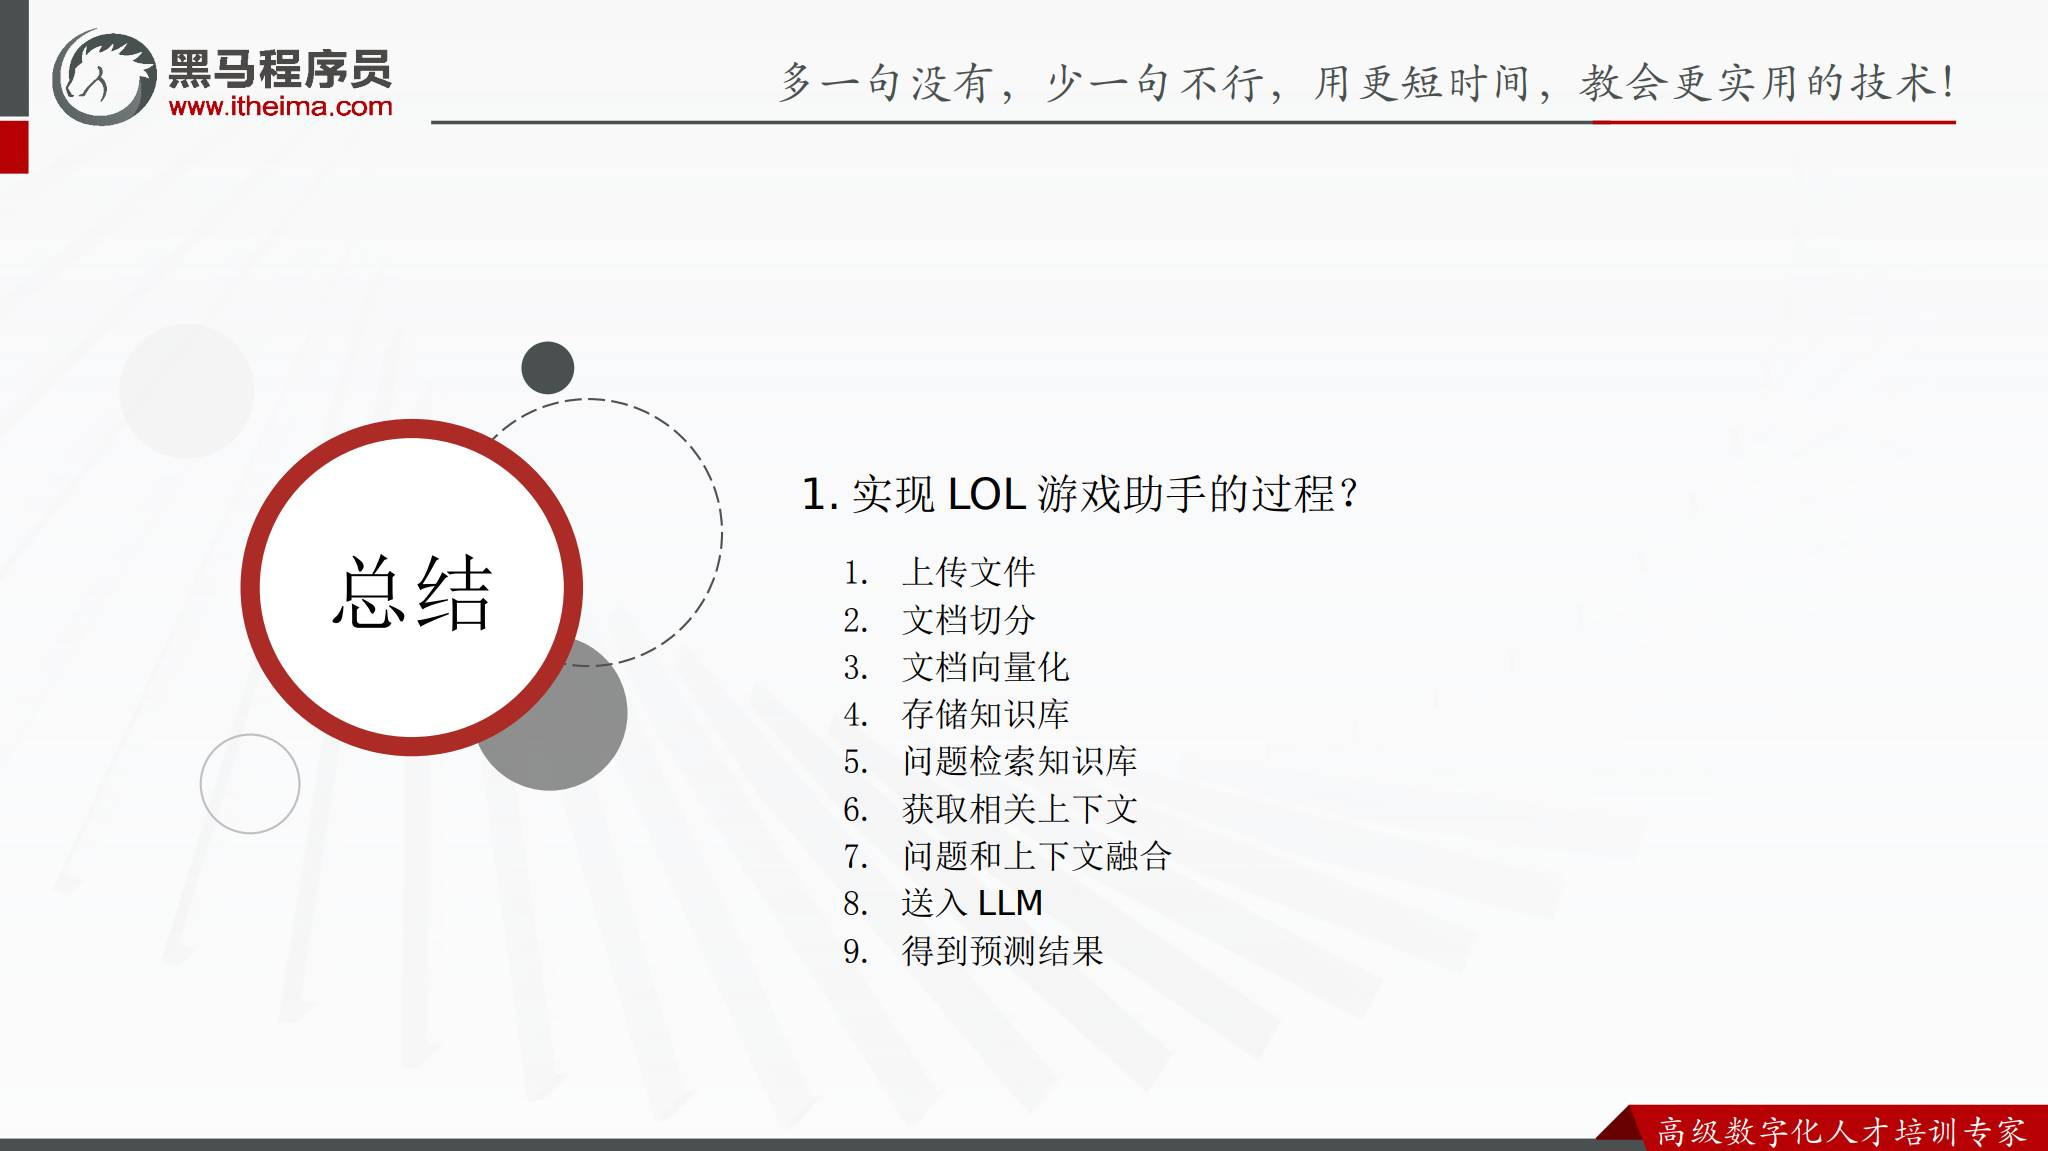


## 12. 如何验证知识库是否生效

调试 Agent 时，可以准备几类问题：

- 资料中明确出现过的英雄或技能名称。
- 用户换一种说法提出的同一问题。
- 知识库中没有出现的内容。
- 同时涉及两个知识库主题的问题。

观察检索到的片段和最终回答，重点检查：

1. 是否找到了正确的文档片段。
2. 片段是否包含回答问题所需的上下文。
3. 模型是否依据检索内容回答。
4. 找不到资料时是否明确说明，而不是自行补造。


## 13. 本章小结

RAG 的核心是“先检索，再生成”。在 Dify 中实现 LOL 游戏助手，需要准备攻略资料，完成文档切分和向量化，创建知识库，再把知识库挂接到 Agent，并通过调试验证检索和回答结果。


## 14. 资料边界

本篇依据第 4 章课件整理了 RAG 原理、知识库文档准备、切片、向量化、检索设置和 LOL 游戏助手流程。课件没有给出具体攻略文件内容、完整字段模板或检索参数数值，因此本篇保留操作顺序和判断原则，不虚构课件之外的数据。
